# EDA Lanjutan (Python) — Copper Smelter Operations Analytics
**PT Nusa Tembaga Smelting (fiktif)** — lanjutan dari `Smelter Operation Cleaning.sql`sql`.

Notebook ini memuat analisis yang lebih pas dikerjakan di Python daripada SQL: visualisasi,
uji korelasi & regresi, radar chart benchmarking, dan forecasting sederhana.

Data yang dipakai adalah hasil query `SELECT * FROM clean.<table>` di PostgreSQL (sudah lolos
data-cleaning), diekspor ke CSV di folder ini. Semua angka pada notebook ini **sintetis**,
dibuat untuk tujuan portofolio, bukan data operasional perusahaan nyata mana pun.

**Daftar isi**
- A. Tren Operasional (feed, produksi, availability)
- B. Downtime — Pareto & MTBF/MTTR
- C. Driver Recovery — korelasi & regresi
- D. Cost & Budget Variance
- E. Peer Benchmarking — radar chart
- F. Tren Grade & Forecast Sep–Des 2026
- G. Rekonsiliasi Stok Konsentrat
- Insight & Rekomendasi (ringkasan)


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
ASSETS_DIR = PROJECT_DIR / "assets"
ASSETS_DIR.mkdir(parents=True, exist_ok=True)

print("Lokasi penyimpanan gambar:", ASSETS_DIR.resolve())

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 10.5,
})
PRIMARY, ACCENT, WARN, GREY = "#1F3864", "#C0642A", "#B00020", "#7F7F7F"

ops   = pd.read_csv("../data/daily_operations.csv", parse_dates=["date"])
evt   = pd.read_csv("../data/downtime_events.csv", parse_dates=["start_datetime", "end_datetime"])
plan  = pd.read_csv("../data/production_plan.csv")
stock = pd.read_csv("../data/concentrate_stock.csv")
cost  = pd.read_csv("../data/cost_report.csv")
peer  = pd.read_csv("../data/peer_benchmark.csv")
mkt   = pd.read_csv("../data/market_reference.csv")

ops["month"] = ops["date"].dt.to_period("M").astype(str)
print(f"daily_operations : {ops.shape[0]} baris, {ops.date.min().date()} s/d {ops.date.max().date()}")
print(f"downtime_events  : {evt.shape[0]} baris")
print(f"cost_report      : {cost.shape[0]} baris ({cost.period_status.eq('Closed').sum()} baris Closed)")
ops.head(3)

Lokasi penyimpanan gambar: C:\DATA ANALIST\DATA CSV\Mine Operation\smelter-operations-analysis\assets
daily_operations : 608 baris, 2025-01-01 s/d 2026-08-31
downtime_events  : 254 baris
cost_report      : 1152 baris (960 baris Closed)


,record_id,date,planned_feed_dmt,concentrate_feed_dmt,feed_cu_pct,feed_au_gpt,feed_sulfur_pct,feed_moisture_pct,oxygen_enrichment_pct,matte_production_t,...,slag_cu_pct,anode_production_t,cathode_production_t,acid_production_t,so2_capture_pct,furnace_availability_pct,energy_consumption_mwh,fuel_oil_kl,operating_status,month
0,OPS-20250101,2025-01-01,2312.0,2343.500000,25.530001,21.299999,30.299999,9.9,67.099998,865.900024,...,1.32,587.900024,581.700012,2097.600098,99.639999,100.000000,741.500000,45.200001,Normal,2025-01
1,OPS-20250102,2025-01-02,2312.0,2124.300049,26.080000,22.400000,31.100000,7.3,66.000000,790.500000,...,1.87,539.799988,528.200012,1952.300049,99.639999,92.400002,723.500000,39.900002,Reduced Rate,2025-01
2,OPS-20250103,2025-01-03,2312.0,1877.300049,26.110001,20.799999,29.500000,8.3,67.300003,710.200012,...,1.48,478.600006,471.399994,1639.199951,99.650002,79.900002,646.799988,37.299999,Reduced Rate,2025-01


## A. Tren Operasional
Feed & produksi bulanan, plan vs actual, dan pola availability.

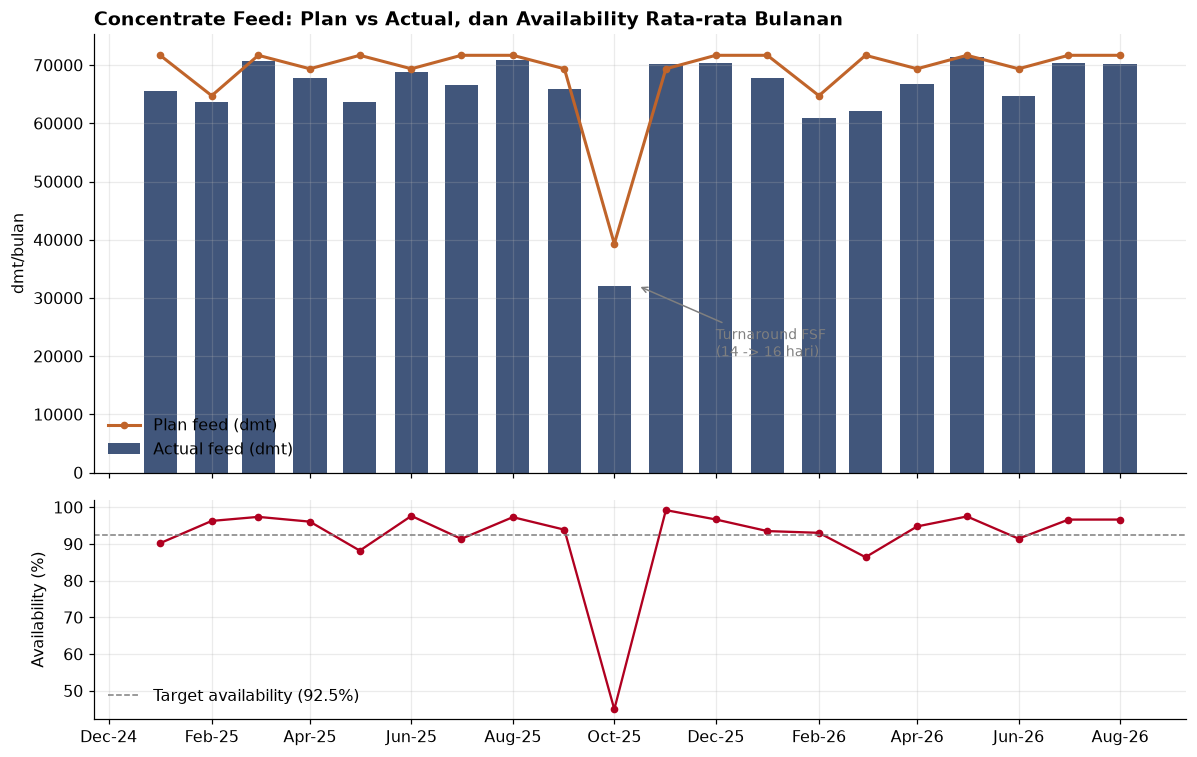

In [4]:
monthly = (ops.groupby("month")
             .agg(feed_dmt=("concentrate_feed_dmt", "sum"),
                  cathode_t=("cathode_production_t", "sum"),
                  acid_t=("acid_production_t", "sum"),
                  avail=("furnace_availability_pct", "mean"))
             .reset_index())
m = monthly.merge(plan[["month", "plan_concentrate_feed_dmt", "plan_cathode_t"]], on="month", how="left")
m["month_dt"] = pd.PeriodIndex(m.month, freq="M").to_timestamp()

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                        gridspec_kw={"height_ratios": [2, 1]})
ax[0].bar(m.month_dt, m.feed_dmt, width=20, color=PRIMARY, alpha=.85, label="Actual feed (dmt)")
ax[0].plot(m.month_dt, m.plan_concentrate_feed_dmt, color=ACCENT, marker="o", ms=4, lw=2, label="Plan feed (dmt)")
ax[0].set_title("Concentrate Feed: Plan vs Actual, dan Availability Rata-rata Bulanan", loc="left", fontweight="bold")
ax[0].set_ylabel("dmt/bulan"); ax[0].legend(frameon=False, loc="lower left")
ax[0].annotate("Turnaround FSF\n(14 -> 16 hari)", xy=(pd.Timestamp("2025-10-15"), m.loc[m.month=="2025-10","feed_dmt"].iloc[0]),
               xytext=(pd.Timestamp("2025-12-01"), 20000), arrowprops=dict(arrowstyle="->", color=GREY), color=GREY, fontsize=9)
ax[1].plot(m.month_dt, m.avail, color=WARN, marker="o", ms=4)
ax[1].axhline(92.5, ls="--", color=GREY, lw=1, label="Target availability (92.5%)")
ax[1].set_ylabel("Availability (%)"); ax[1].legend(frameon=False, loc="lower left")
ax[1].xaxis.set_major_locator(plt.matplotlib.dates.MonthLocator(interval=2))
ax[1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b-%y"))
plt.xticks(rotation=0)
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_A1_plan_vs_actual.png", bbox_inches="tight"); plt.show()

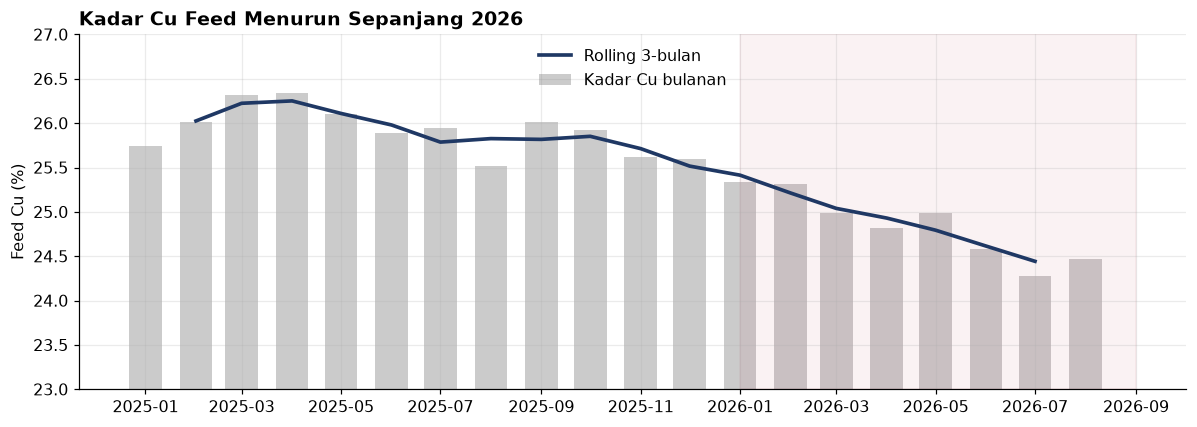

Slope grade 2025: -0.47 pp/tahun (annualized)  |  2026: -1.75 pp/tahun (annualized)


In [5]:
# Kadar Cu feed tertimbang per bulan (dua kali PERCENTILE_CONT/weighted average di SQL, diverifikasi ulang di sini)
w = (ops.assign(cu_x_feed=ops.feed_cu_pct * ops.concentrate_feed_dmt)
        .groupby("month").agg(feed_dmt=("concentrate_feed_dmt", "sum"), cu_x=("cu_x_feed", "sum")))
w["feed_cu_pct_w"] = w.cu_x / w.feed_dmt
w = w.reset_index(); w["month_dt"] = pd.PeriodIndex(w.month, freq="M").to_timestamp()
w["roll3"] = w.feed_cu_pct_w.rolling(3, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(w.month_dt, w.feed_cu_pct_w, width=20, color=GREY, alpha=.4, label="Kadar Cu bulanan")
ax.plot(w.month_dt, w.roll3, color=PRIMARY, lw=2.4, label="Rolling 3-bulan")
ax.axvspan(pd.Timestamp("2026-01-01"), pd.Timestamp("2026-09-01"), color=WARN, alpha=.05)
ax.set_title("Kadar Cu Feed Menurun Sepanjang 2026", loc="left", fontweight="bold")
ax.set_ylabel("Feed Cu (%)"); ax.set_ylim(23, 27); ax.legend(frameon=False)
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_A2_grade_trend.png", bbox_inches="tight"); plt.show()

slope_25 = stats.linregress(range((w.month<"2026").sum()), w.loc[w.month<"2026","feed_cu_pct_w"]).slope
slope_26 = stats.linregress(range((w.month>="2026").sum()), w.loc[w.month>="2026","feed_cu_pct_w"]).slope
print(f"Slope grade 2025: {slope_25*12:+.2f} pp/tahun (annualized)  |  2026: {slope_26*12:+.2f} pp/tahun (annualized)")

## B. Downtime — Pareto & MTBF/MTTR
Mana yang paling layak jadi prioritas maintenance / production meeting.

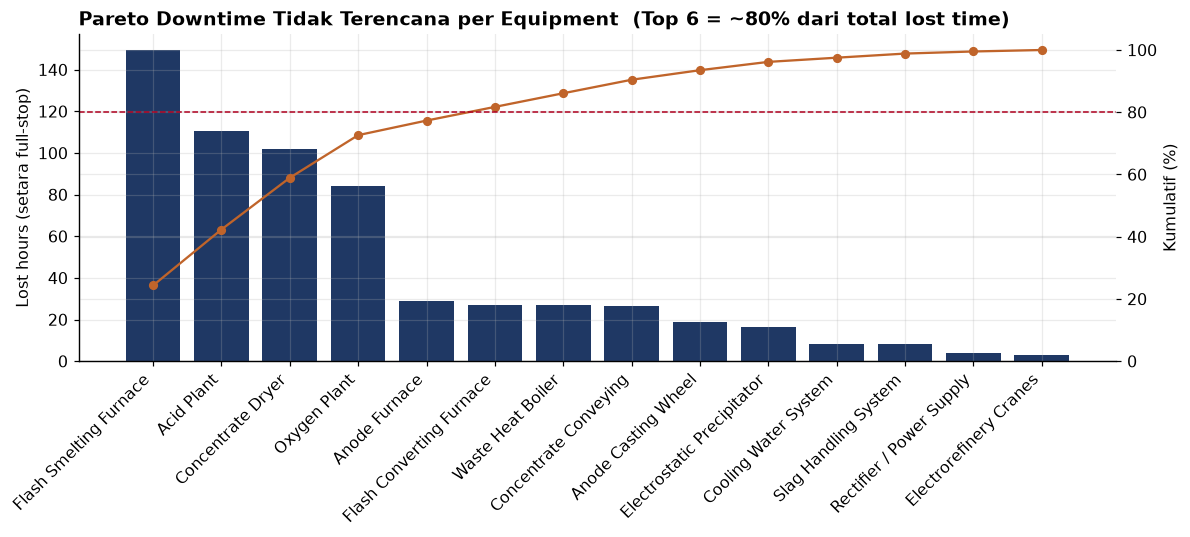

Equipment prioritas (kontribusi ke 80% pertama):
               equipment  lost_hr_equiv   cum_pct
  Flash Smelting Furnace        149.485 24.339788
              Acid Plant        110.423 42.319334
       Concentrate Dryer        102.113 58.945810
            Oxygen Plant         84.099 72.639170
           Anode Furnace         28.769 77.323462
Flash Converting Furnace         27.000 81.719718


In [6]:
unpl = evt[(evt.is_planned == "N") & (evt.impact_type != "No Impact")].copy()
unpl["lost_hr_equiv"] = unpl.duration_hr * unpl.throughput_loss_pct / 100

par = (unpl.groupby("equipment").lost_hr_equiv.sum().sort_values(ascending=False).reset_index())
par["cum_pct"] = 100 * par.lost_hr_equiv.cumsum() / par.lost_hr_equiv.sum()

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.bar(par.equipment, par.lost_hr_equiv, color=PRIMARY)
ax1.set_ylabel("Lost hours (setara full-stop)"); ax1.tick_params(axis="x", rotation=45)
for lbl in ax1.get_xticklabels(): lbl.set_ha("right")
ax2 = ax1.twinx()
ax2.plot(par.equipment, par.cum_pct, color=ACCENT, marker="o", ms=5)
ax2.axhline(80, ls="--", color=WARN, lw=1)
ax2.set_ylabel("Kumulatif (%)"); ax2.set_ylim(0, 105)
cutoff = (par.cum_pct <= 80).sum() + 1
ax1.set_title(f"Pareto Downtime Tidak Terencana per Equipment  (Top {cutoff} = ~80% dari total lost time)",
              loc="left", fontweight="bold")
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_B1_pareto_equipment.png", bbox_inches="tight"); plt.show()

print("Equipment prioritas (kontribusi ke 80% pertama):")
print(par.head(cutoff)[["equipment", "lost_hr_equiv", "cum_pct"]].to_string(index=False))

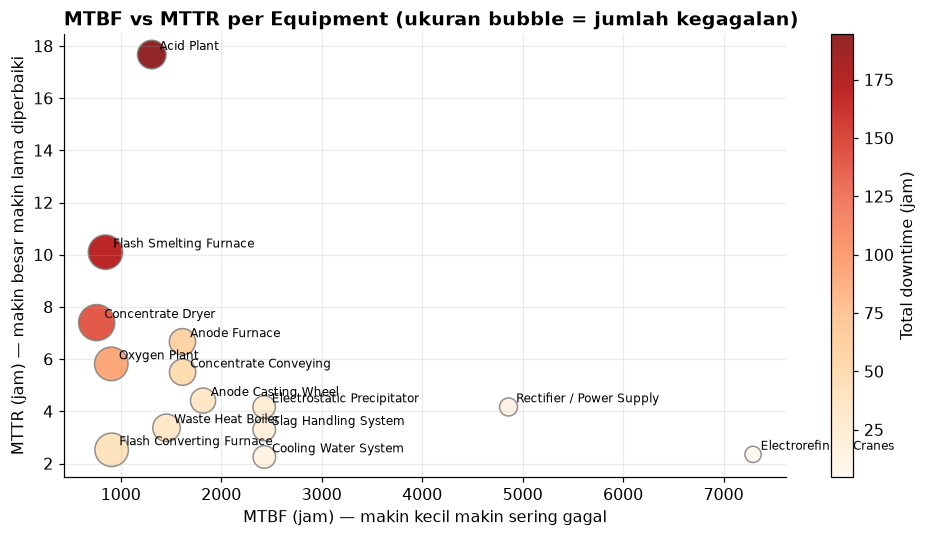


Kandidat prioritas RCA (MTBF rendah & MTTR tinggi -> kuadran kiri-atas):
                          failures  down_hr  mttr_hr  mtbf_hr
equipment                                                    
Concentrate Dryer               19    140.6      7.4    760.6
Flash Smelting Furnace          17    171.7     10.1    848.3
Oxygen Plant                    16     93.1      5.8    906.2
Flash Converting Furnace        16     40.4      2.5    909.5


In [7]:
period_hr = ops.shape[0] * 24
mtbf = (unpl.groupby("equipment")
            .agg(failures=("event_id", "count"), down_hr=("duration_hr", "sum"))
            .assign(mttr_hr=lambda d: d.down_hr / d.failures,
                    mtbf_hr=lambda d: (period_hr - d.down_hr) / d.failures)
            .sort_values("mtbf_hr"))

fig, ax = plt.subplots(figsize=(9, 5))
sizes = (mtbf.failures / mtbf.failures.max() * 500) + 60
sc = ax.scatter(mtbf.mtbf_hr, mtbf.mttr_hr, s=sizes, c=mtbf.down_hr, cmap="OrRd", edgecolor=GREY, alpha=.85)
for name, row in mtbf.iterrows():
    ax.annotate(name, (row.mtbf_hr, row.mttr_hr), fontsize=8, xytext=(5, 3), textcoords="offset points")
ax.set_xlabel("MTBF (jam) — makin kecil makin sering gagal")
ax.set_ylabel("MTTR (jam) — makin besar makin lama diperbaiki")
ax.set_title("MTBF vs MTTR per Equipment (ukuran bubble = jumlah kegagalan)", loc="left", fontweight="bold")
plt.colorbar(sc, label="Total downtime (jam)")
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_B2_mtbf_mttr.png", bbox_inches="tight"); plt.show()
print("\nKandidat prioritas RCA (MTBF rendah & MTTR tinggi -> kuadran kiri-atas):")
print(mtbf.sort_values(["mtbf_hr", "mttr_hr"]).head(4).round(1))

## C. Driver Recovery — Korelasi & Regresi
Apakah oxygen enrichment berkorelasi dengan matte grade? Adakah trade-off dengan slag Cu loss?

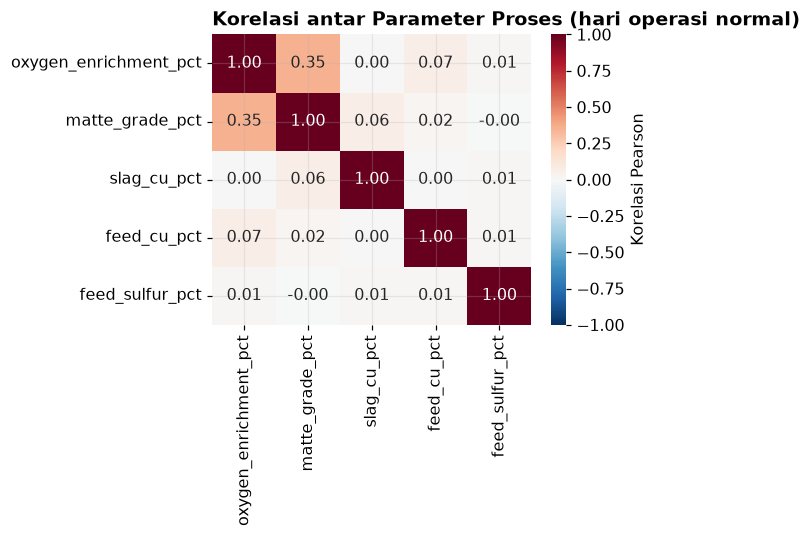

In [8]:
run = ops[ops.furnace_availability_pct > 90].copy()
cols = ["oxygen_enrichment_pct", "matte_grade_pct", "slag_cu_pct", "feed_cu_pct", "feed_sulfur_pct"]
corr = run[cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            cbar_kws={"label": "Korelasi Pearson"}, ax=ax)
ax.set_title("Korelasi antar Parameter Proses (hari operasi normal)", loc="left", fontweight="bold")
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_C1_corr_heatmap.png", bbox_inches="tight"); plt.show()

                            OLS Regression Results                            
Dep. Variable:        matte_grade_pct   R-squared:                       0.124
Model:                            OLS   Adj. R-squared:                  0.122
Method:                 Least Squares   F-statistic:                     70.78
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           4.21e-16
Time:                        18:57:01   Log-Likelihood:                -801.04
No. Observations:                 502   AIC:                             1606.
Df Residuals:                     500   BIC:                             1615.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    53.21

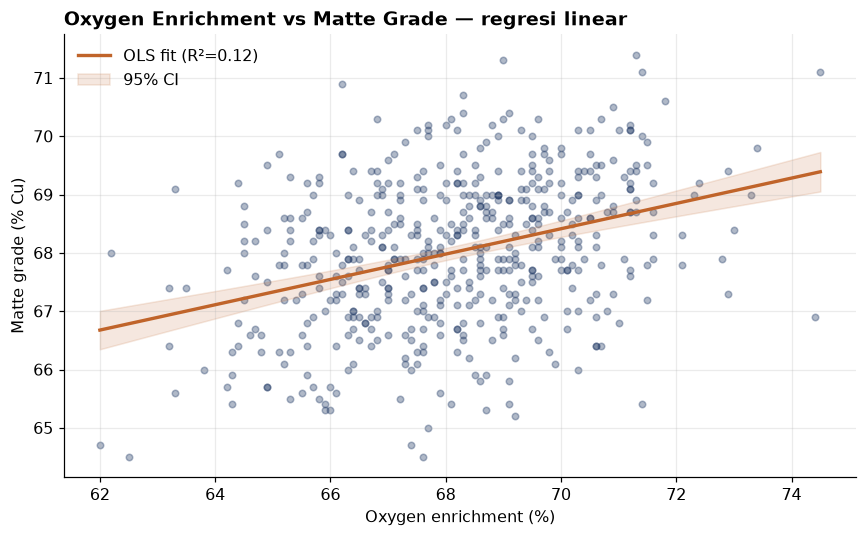


Setiap +1% oxygen enrichment -> matte grade berubah +0.217 pp (p=0.0000, signifikan pada alpha=0.05).
Catatan: ini korelasi observasional pada data operasi harian, BUKAN bukti sebab-akibat definitif -
perlu dikonfirmasi dengan data uji coba terkendali (plant trial) sebelum jadi dasar keputusan operasi.


In [9]:
X = sm.add_constant(run["oxygen_enrichment_pct"])
y = run["matte_grade_pct"]
model = sm.OLS(y, X).fit()
print(model.summary())

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(run.oxygen_enrichment_pct, run.matte_grade_pct, alpha=.35, color=PRIMARY, s=18)
xs = np.linspace(run.oxygen_enrichment_pct.min(), run.oxygen_enrichment_pct.max(), 50)
pred = model.get_prediction(sm.add_constant(xs)).summary_frame(alpha=0.05)
ax.plot(xs, pred["mean"], color=ACCENT, lw=2.2, label=f"OLS fit (R\u00b2={model.rsquared:.2f})")
ax.fill_between(xs, pred["mean_ci_lower"], pred["mean_ci_upper"], color=ACCENT, alpha=.15, label="95% CI")
ax.set_xlabel("Oxygen enrichment (%)"); ax.set_ylabel("Matte grade (% Cu)")
ax.set_title("Oxygen Enrichment vs Matte Grade — regresi linear", loc="left", fontweight="bold")
ax.legend(frameon=False)
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_C2_o2_vs_mattegrade.png", bbox_inches="tight"); plt.show()

coef = model.params["oxygen_enrichment_pct"]; p = model.pvalues["oxygen_enrichment_pct"]
print(f"\nSetiap +1% oxygen enrichment -> matte grade berubah {coef:+.3f} pp (p={p:.4f}, {'signifikan' if p<0.05 else 'tidak signifikan'} pada alpha=0.05).")
print("Catatan: ini korelasi observasional pada data operasi harian, BUKAN bukti sebab-akibat definitif -")
print("perlu dikonfirmasi dengan data uji coba terkendali (plant trial) sebelum jadi dasar keputusan operasi.")

## D. Cost & Budget Variance
Budget vs actual bulanan dan variance per cost center (baris tanpa actual dikeluarkan, bukan dianggap 0).

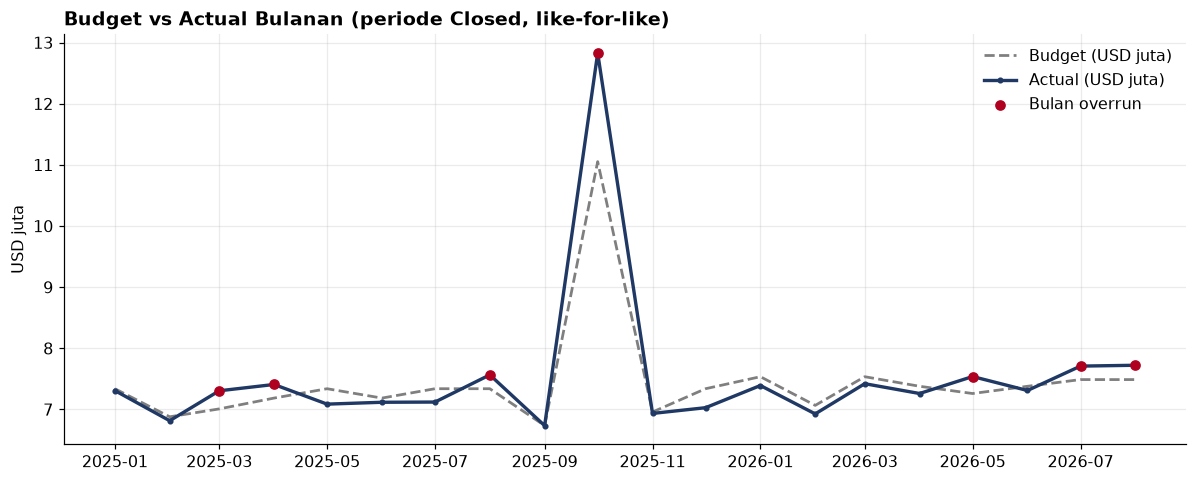

In [10]:
cmp = cost[(cost.period_status == "Closed") & cost.actual_usd.notna()].copy()
mo = (cmp.groupby("period").agg(budget=("budget_usd", "sum"), actual=("actual_usd", "sum")).reset_index())
mo["month_dt"] = pd.PeriodIndex(mo.period, freq="M").to_timestamp()
mo["var_usd"] = mo.actual - mo.budget
mo["var_pct"] = 100 * mo.var_usd / mo.budget

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(mo.month_dt, mo.budget/1e6, color=GREY, lw=1.8, ls="--", label="Budget (USD juta)")
ax.plot(mo.month_dt, mo.actual/1e6, color=PRIMARY, lw=2.2, marker="o", ms=3, label="Actual (USD juta)")
over = mo[mo.var_usd > 0]
ax.scatter(over.month_dt, over.actual/1e6, color=WARN, zorder=5, label="Bulan overrun")
ax.set_title("Budget vs Actual Bulanan (periode Closed, like-for-like)", loc="left", fontweight="bold")
ax.set_ylabel("USD juta"); ax.legend(frameon=False)
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_D1_budget_vs_actual.png", bbox_inches="tight"); plt.show()

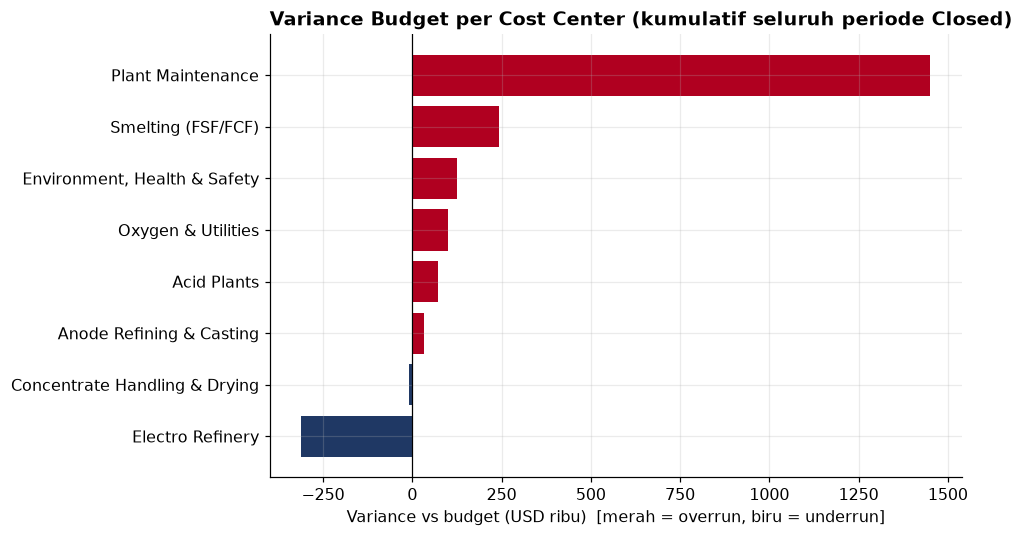

In [11]:
cc = (cmp.groupby("cost_center").agg(budget=("budget_usd", "sum"), actual=("actual_usd", "sum"))
         .assign(var_usd=lambda d: d.actual - d.budget).sort_values("var_usd"))

colors = [WARN if v > 0 else PRIMARY for v in cc.var_usd]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(cc.index, cc.var_usd/1e3, color=colors)
ax.axvline(0, color="black", lw=.8)
ax.set_xlabel("Variance vs budget (USD ribu)  [merah = overrun, biru = underrun]")
ax.set_title("Variance Budget per Cost Center (kumulatif seluruh periode Closed)", loc="left", fontweight="bold")
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_D2_variance_by_center.png", bbox_inches="tight"); plt.show()

## E. Peer Benchmarking — Radar Chart
Posisi own plant vs median peer vs kuartil teratas, tahun 2025. Skala dinormalisasi 0-100 (100 = kuartil teratas).

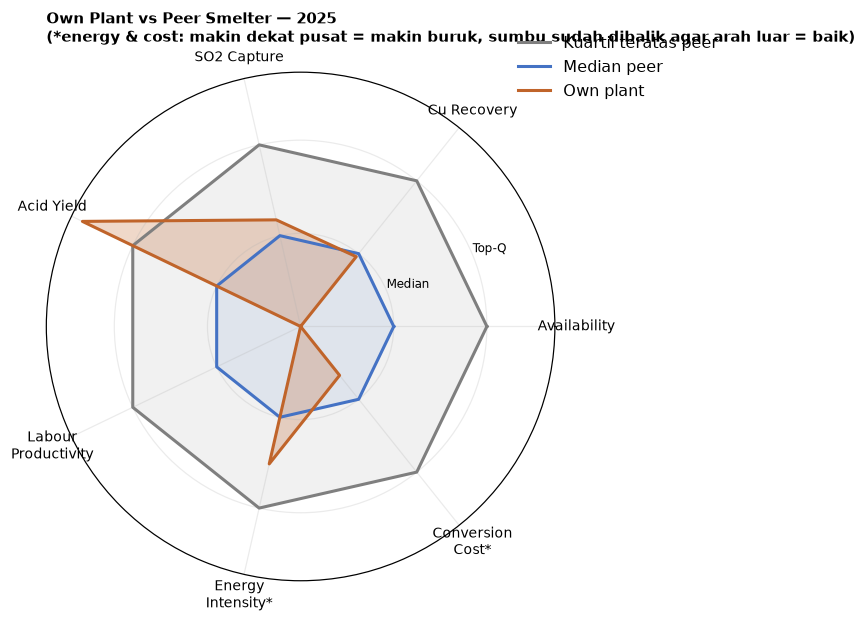

                             kpi  own_raw    own
                availability_pct    90.67   0.00
                 cu_recovery_pct    97.86  47.91
                 so2_capture_pct    99.60  58.70
           acid_yield_t_per_t_cu     3.68 130.00
labour_productivity_t_cu_per_fte   219.80   0.00
    energy_intensity_gj_per_t_cu     7.84  75.68
    conversion_cost_usd_per_t_cu   476.88  33.57

Gap terbesar ke kuartil teratas: labour productivity & conversion cost -> prioritas improvement 2026.


In [12]:
kpis = {
    "availability_pct": True, "cu_recovery_pct": True, "so2_capture_pct": True,
    "acid_yield_t_per_t_cu": True, "labour_productivity_t_cu_per_fte": True,
    "energy_intensity_gj_per_t_cu": False, "conversion_cost_usd_per_t_cu": False,
}
p25 = peer[peer.benchmark_year == 2025].copy()
p25["labour_productivity_t_cu_per_fte"] = pd.to_numeric(p25.labour_productivity_t_cu_per_fte, errors="coerce")
peers_only = p25[p25.smelter_id != "OWN-PLANT"]
own = p25[p25.smelter_id == "OWN-PLANT"].iloc[0]

rows = []
for k, higher_better in kpis.items():
    med = peers_only[k].median()
    topq = peers_only[k].quantile(.75 if higher_better else .25)
    ownv = own[k]
    # normalisasi 0-100 relatif terhadap median(=50) dan kuartil-teratas(=100), searah "makin tinggi makin baik"
    span = (topq - med) if higher_better else (med - topq)
    def norm(v): return float(np.clip(50 + 50 * ((v - med) / span if higher_better else (med - v) / span), 0, 130))
    rows.append(dict(kpi=k, own=norm(ownv), peer_median=50.0, top_quartile=100.0, own_raw=ownv))
rad = pd.DataFrame(rows)
labels = ["Availability", "Cu Recovery", "SO2 Capture", "Acid Yield", "Labour\nProductivity", "Energy\nIntensity*", "Conversion\nCost*"]

angles = np.linspace(0, 2*np.pi, len(rad), endpoint=False).tolist(); angles += angles[:1]
fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
for col, color, lbl, alpha in [("top_quartile", GREY, "Kuartil teratas peer", .10),
                                 ("peer_median", "#4472C4", "Median peer", .10),
                                 ("own", ACCENT, "Own plant", .25)]:
    vals = rad[col].tolist(); vals += vals[:1]
    ax.plot(angles, vals, color=color, lw=2, label=lbl)
    ax.fill(angles, vals, color=color, alpha=alpha)
ax.set_xticks(angles[:-1]); ax.set_xticklabels(labels, fontsize=9)
ax.set_yticks([0, 50, 100]); ax.set_yticklabels(["0", "Median", "Top-Q"], fontsize=8)
ax.set_title("Own Plant vs Peer Smelter — 2025\n(*energy & cost: makin dekat pusat = makin buruk, sumbu sudah dibalik agar arah luar = baik)",
             loc="left", fontsize=10, fontweight="bold")
ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1), frameon=False)
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_E1_radar_benchmark.png", bbox_inches="tight"); plt.show()

print(rad[["kpi", "own_raw", "own"]].round(2).to_string(index=False))
print("\nGap terbesar ke kuartil teratas: labour productivity & conversion cost -> prioritas improvement 2026.")

## F. Tren Grade & Forecast Sep–Des 2026
Forecast sederhana (regresi linear atas tren 2026) dibandingkan dengan Plan (Re-forecast Jul-2026).

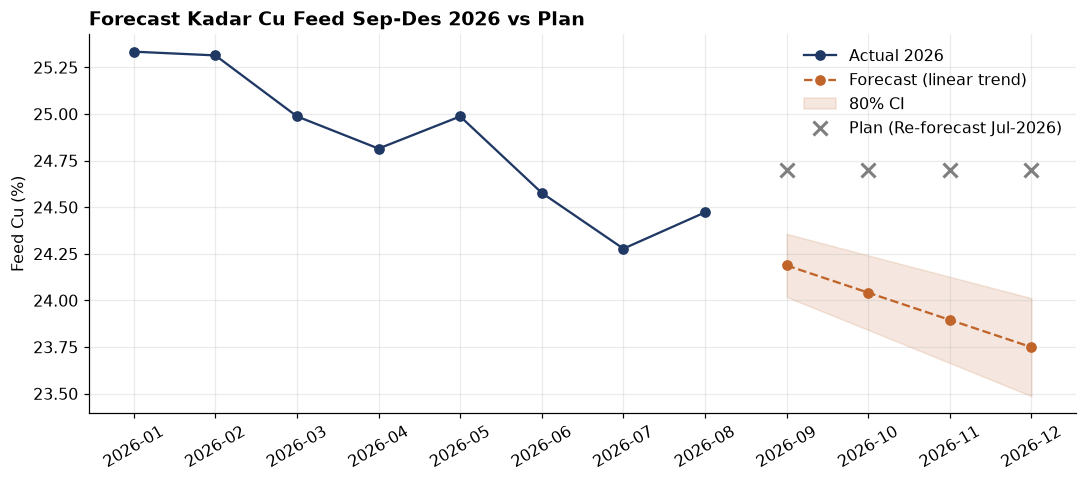

         forecast_cu_pct  plan_cu_pct  gap_pct_pt
2026-09            24.19         24.7       -0.51
2026-10            24.04         24.7       -0.66
2026-11            23.90         24.7       -0.80
2026-12            23.75         24.7       -0.95

Catatan: forecast linear sederhana untuk ilustrasi tren, bukan model produksi. Untuk keputusan bisnis,
pertimbangkan model time-series yang lebih robust (mis. Holt-Winters) dan validasi dengan data geologi/mine plan.


In [13]:
g26 = w[w.month >= "2026-01"].reset_index(drop=True)
g26["t"] = range(len(g26))
X = sm.add_constant(g26.t); y = g26.feed_cu_pct_w
gm = sm.OLS(y, X).fit()

future_t = range(len(g26), len(g26) + 4)  # Sep, Okt, Nov, Des 2026
future_months = pd.period_range("2026-09", "2026-12", freq="M")
fc = gm.get_prediction(sm.add_constant(list(future_t))).summary_frame(alpha=.2)
fc.index = future_months.astype(str)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(g26.month, g26.feed_cu_pct_w, "o-", color=PRIMARY, label="Actual 2026")
ax.plot(fc.index, fc["mean"], "o--", color=ACCENT, label="Forecast (linear trend)")
ax.fill_between(range(len(g26), len(g26)+len(fc)), fc.mean_ci_lower, fc.mean_ci_upper, color=ACCENT, alpha=.15, label="80% CI")
plan26 = plan[plan.month.between("2026-09", "2026-12")]
ax.plot(plan26.month, plan26.plan_feed_cu_pct, "x", color=GREY, ms=9, mew=2, label="Plan (Re-forecast Jul-2026)")
ax.set_ylabel("Feed Cu (%)"); ax.set_title("Forecast Kadar Cu Feed Sep-Des 2026 vs Plan", loc="left", fontweight="bold")
ax.tick_params(axis="x", rotation=30); ax.legend(frameon=False)
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_F1_grade_forecast.png", bbox_inches="tight"); plt.show()

comp = fc[["mean"]].rename(columns={"mean": "forecast_cu_pct"}).round(2)
comp["plan_cu_pct"] = plan26.set_index(plan26.month.astype(str)).plan_feed_cu_pct.values
comp["gap_pct_pt"] = (comp.forecast_cu_pct - comp.plan_cu_pct).round(2)
print(comp)
print("\nCatatan: forecast linear sederhana untuk ilustrasi tren, bukan model produksi. Untuk keputusan bisnis,")
print("pertimbangkan model time-series yang lebih robust (mis. Holt-Winters) dan validasi dengan data geologi/mine plan.")

## G. Rekonsiliasi Stok Konsentrat
Bulan mana yang selisih neraca stoknya signifikan (>1% dari feed bulanan) dan perlu investigasi manual.

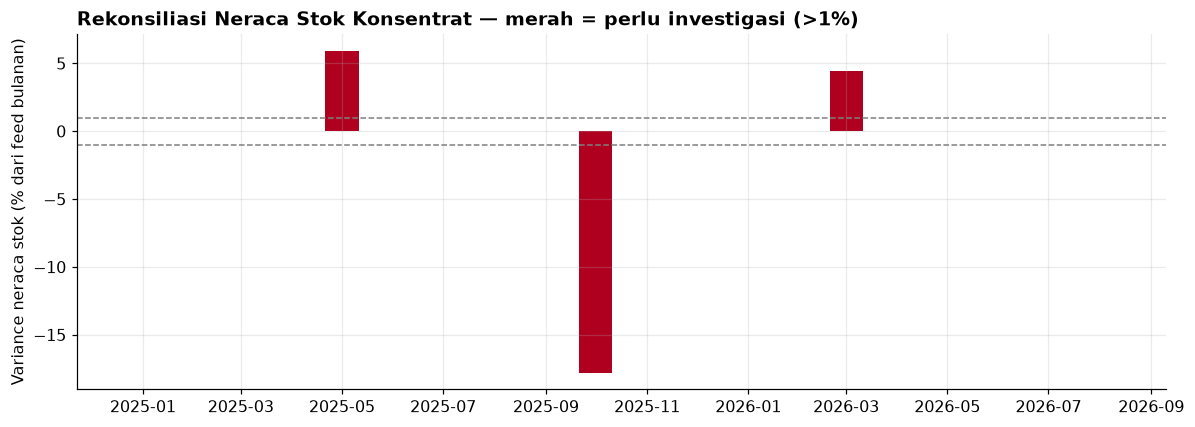

  month  reconciliation_variance_dmt  variance_pct_of_feed
2025-05                       3790.0                  5.95
2025-10                      -5724.0                -17.82
2026-03                       2771.0                  4.47


In [14]:
st = stock.merge(monthly[["month", "feed_dmt"]], on="month")
st["variance_pct_of_feed"] = 100 * st.reconciliation_variance_dmt / st.feed_dmt
st["month_dt"] = pd.PeriodIndex(st.month, freq="M").to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4))
colors = [WARN if abs(v) > 1 else PRIMARY for v in st.variance_pct_of_feed]
ax.bar(st.month_dt, st.variance_pct_of_feed, width=20, color=colors)
ax.axhline(1, ls="--", color=GREY, lw=1); ax.axhline(-1, ls="--", color=GREY, lw=1)
ax.set_ylabel("Variance neraca stok (% dari feed bulanan)")
ax.set_title("Rekonsiliasi Neraca Stok Konsentrat — merah = perlu investigasi (>1%)", loc="left", fontweight="bold")
fig.tight_layout(); plt.savefig(ASSETS_DIR / "fig_G1_stock_reconciliation.png", bbox_inches="tight"); plt.show()

print(st.loc[st.variance_pct_of_feed.abs() > 1, ["month", "reconciliation_variance_dmt", "variance_pct_of_feed"]]
        .round(2).to_string(index=False))

## Insight & Rekomendasi (ringkasan)

**Operasional**
- Variance feed bulanan didominasi oleh **availability**, bukan laju feed — prioritaskan perbaikan uptime, bukan sekadar mendorong throughput saat plant jalan.
- Equipment dengan kontribusi lost-time terbesar (lihat Pareto B1) adalah kandidat utama untuk inisiatif preventive maintenance 2027.

**Cost & Budget**
- Overrun terbesar terjadi pada bulan turnaround (Okt-2025), terutama Contractors & Services dan Refractory & Spares — evaluasi kontrak dan estimasi durasi turnaround berikutnya.

**Benchmarking**
- Gap terbesar terhadap kuartil teratas peer ada pada **produktivitas tenaga kerja** dan **conversion cost** — dua area ini punya potensi improvement terbesar untuk 2026-2027.

**PPC**
- Tren penurunan kadar Cu feed di 2026 berisiko membuat plan Sep-Des 2026 optimis — pertimbangkan revisi plan mengikuti forecast tren aktual, dikonfirmasi dengan data mine plan/geologi.

**Data Quality**
- 3 bulan pada neraca stok konsentrat (Mei-2025, Okt-2025, Mar-2026) belum rekonsiliasi — perlu klarifikasi ke tim gudang/PPC sebelum dipakai sebagai dasar keputusan pembelian konsentrat.

> Seluruh angka pada notebook ini adalah data sintetis untuk tujuan portofolio.
